In [6]:
#Import all needed libraries
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

%matplotlib inline

In [8]:
df = pd.read_csv(r"../../Day_1/lab-eda-univariate/amz_uk_price_prediction_dataset.csv")

In [10]:
display(df.head())

,uid,asin,title,stars,reviews,price,isBestSeller,boughtInLastMonth,category
0,1,B09B96TG33,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
1,2,B01HTH3C8S,"Anker Soundcore mini, Super-Portable Bluetooth...",4.7,98099,23.99,True,0,Hi-Fi Speakers
2,3,B09B8YWXDF,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
3,4,B09B8T5VGV,"Echo Dot with clock (5th generation, 2022 rele...",4.7,7205,31.99,False,0,Hi-Fi Speakers
4,5,B09WX6QD65,Introducing Echo Pop | Full sound compact Wi-F...,4.6,1881,17.99,False,0,Hi-Fi Speakers


In [49]:
#1a **Crosstab Analysis**: Create a crosstab between the product `category` and the `isBestSeller` status.
crosstab_cat_best = pd.crosstab(df["category"], df["isBestSeller"])
display(crosstab_cat_best.sort_values(by=True, ascending=False))


#1b **Crosstab Analysis**: - Are there categories where being a best-seller is more prevalent? 
prop_crosstab = (crosstab_cat_best/(crosstab_cat_best.sum())).round(2).sort_values(by=True,ascending=False)
display(prop_crosstab)

isBestSeller,False,True
category,,
Grocery,9008,556
Health & Personal Care,9017,552
Baby,14709,341
Sports & Outdoors,835935,330
Power & Hand Tools,8353,306
...,...,...
Downhill Ski Boots,1284,0
Digital Frames,774,0
Motorbike Chassis,107,0


isBestSeller,False,True
category,,
Grocery,0.00,0.07
Health & Personal Care,0.00,0.07
Sports & Outdoors,0.34,0.04
Power & Hand Tools,0.00,0.04
Beauty,0.01,0.04
...,...,...
Handmade Artwork,0.01,0.00
Handmade Baby Products,0.00,0.00
"Handmade Clothing, Shoes & Accessories",0.01,0.00


Yes, some categories have many more best sellers.

In [56]:
#2a **Statistical Tests**: Conduct a Chi-square test to determine if the best-seller distribution is independent of the product category.
from scipy.stats import chi2_contingency

chi2_statistic, chi2_p_value, _, expected_freq = chi2_contingency(crosstab_cat_best)

display(chi2_statistic, chi2_p_value, _)

36540.20270061387

0.0

295

#Initial impression is null hypothesis of complete independence is untrue (with some reservations around certain data)

In [52]:
pd.DataFrame(expected_freq, columns = df["isBestSeller"].unique(), index = crosstab_cat_best.index).round(0)

,False,True
category,,
3D Printers,247.0,1.0
3D Printing & Scanning,4054.0,13.0
Abrasive & Finishing Products,249.0,1.0
Action Cameras,1691.0,6.0
Adapters,253.0,1.0
...,...,...
Wind Instruments,249.0,1.0
Window Treatments,238.0,1.0
Women,17714.0,58.0


In [58]:
#2b **Statistical Tests**: Compute Cramér's V to understand the strength of association between best-seller status and category.
from scipy.stats.contingency import association

association(crosstab_cat_best, method = "cramer")

0.1222829439760564

Kramer suggests a weak association between BestSeller and Category

<Axes: xlabel='category'>

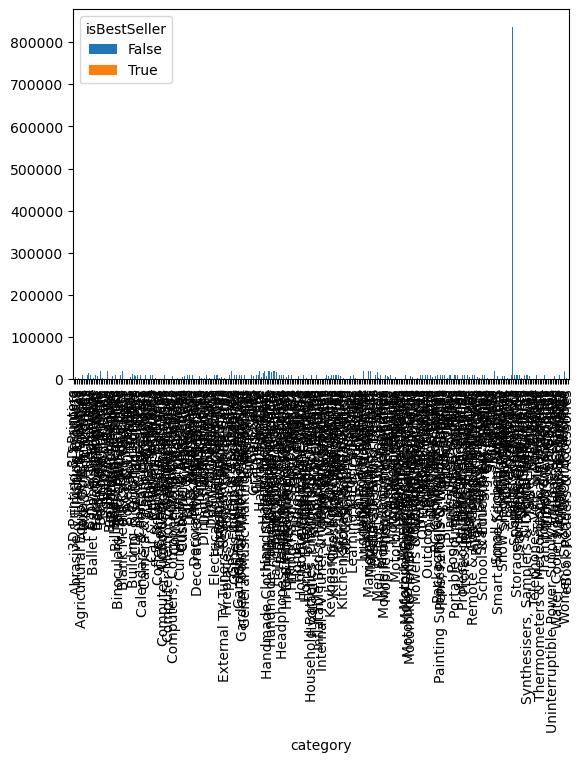

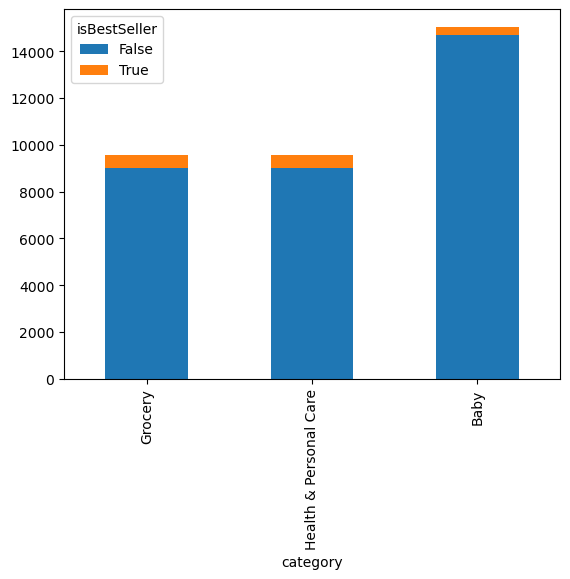

In [63]:
#3. **Visualizations**: Visualize the relationship between product categories and the best-seller status using a stacked bar chart.
crosstab_cat_best.plot(kind = "bar", stacked = True)

sorted_crosscat = crosstab_cat_best.sort_values(by=True, ascending=False).head(3)
sorted_crosscat.plot(kind = "bar", stacked = True)

### Part 2: Exploring Product Prices and Ratings Across Categories and Brand
**Objective**: Investigate how different product categories influence product prices.

In [64]:
#0 Preliminary Step: Remove outliers in product prices.
def tukeys_test_outliers(data):
    Q1 = data.quantile(0.25)
    Q3 = data.quantile(0.75)
    IQR = Q3 - Q1

    #Define lower bound
    lower_bound = Q1 - IQR * 1.5
    upper_bound = Q3 + IQR * 1.5

    # Identify the outliers
    outliers = data[(data > upper_bound) | (data < lower_bound)]
    return outliers

In [75]:
product_prices = df["price"]
outlier_prices = tukeys_test_outliers(product_prices)
print(outlier_prices)
print(type(outlier_prices))

10         139.00
19         164.99
25         149.99
28         289.00
31         199.99
            ...  
2443619    166.99
2443627    152.58
2443638    108.77
2443641    166.99
2443643    158.99
Name: price, Length: 327688, dtype: float64
<class 'pandas.core.series.Series'>


In [76]:
df_ex_outliers = df.drop(index = outlier_prices.index)

In [80]:
#Check on outliers
display(df_ex_outliers[df_ex_outliers["price"] > 139])

,uid,asin,title,stars,reviews,price,isBestSeller,boughtInLastMonth,category


<Axes: xlabel='category', ylabel='price'>

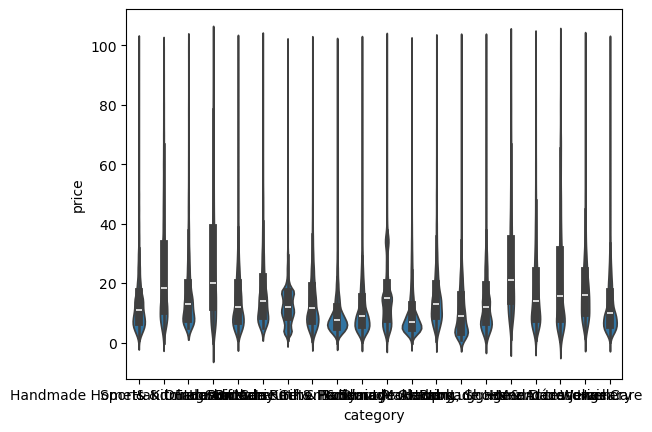

In [98]:
#1a **Violin Plots**: Use a violin plot to visualize the distribution of `price` across different product `categories`. Filter out the top 20 categories based on count for better visualization.

top_20_category = df_ex_outliers["category"].value_counts(ascending=False).head(20)

df_ex_outliters_top_cat = df_ex_outliers[df_ex_outliers["category"].isin(top_20_category.index)]

sns.violinplot(data=df_ex_outliters_top_cat, x="category", y="price") 

In [107]:
#1b Which product category tends to have the highest median price? Don't filter here by top categories.
med_cat_price = df_ex_outliers.groupby("category")['price'].median()
display(med_cat_price.sort_values(ascending=False))

category
Desktop PCs              74.00
Boxing Shoes             69.79
Tablets                  69.00
Graphics Cards           68.54
Motherboards             67.92
                         ...  
Adapters                  7.05
Make-up                   7.00
Signs & Plaques           6.99
Arts & Crafts             5.99
Office Paper Products     4.37
Name: price, Length: 296, dtype: float64

In [116]:
#2a **Bar Charts**: Create a bar chart comparing the average price of products for the top 10 product categories (based on count).
top_10_category = df_ex_outliers["category"].value_counts(ascending=False).head(10)
df_ex_outliers_top_10 = df_ex_outliers[df_ex_outliers["category"].isin(top_10_category.index)]

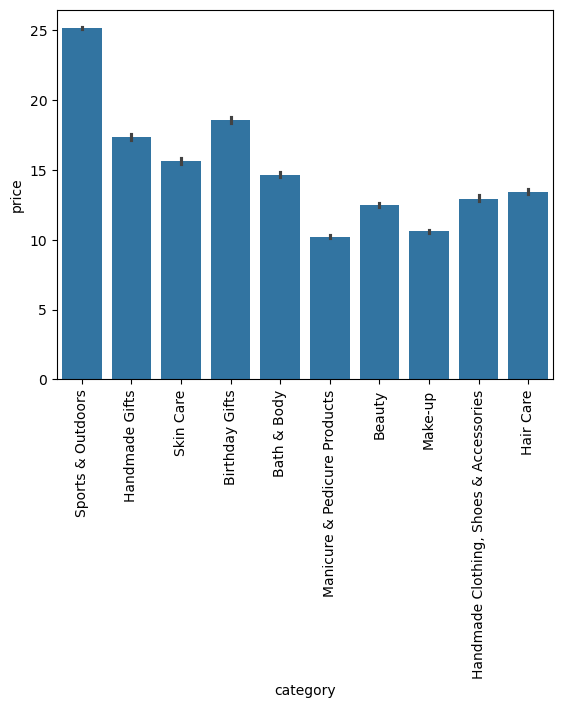

In [118]:
sns.barplot(x="category", y="price", data=df_ex_outliers_top_10)
plt.xticks(rotation=90)
plt.show()

In [123]:
#2b Which product category commands the highest average price? Don't filter here by top categories.
mean_cat_price = df_ex_outliers.groupby("category")['price'].mean()
display(mean_cat_price.sort_values(ascending=False))

category
Motherboards             68.772432
Boxing Shoes             67.417803
Desktop PCs              66.915562
Tablets                  66.552971
Graphics Cards           65.103509
                           ...    
Bedding Accessories       8.835220
Adapters                  8.750197
Signs & Plaques           8.210513
Arts & Crafts             8.006540
Office Paper Products     6.876369
Name: price, Length: 296, dtype: float64

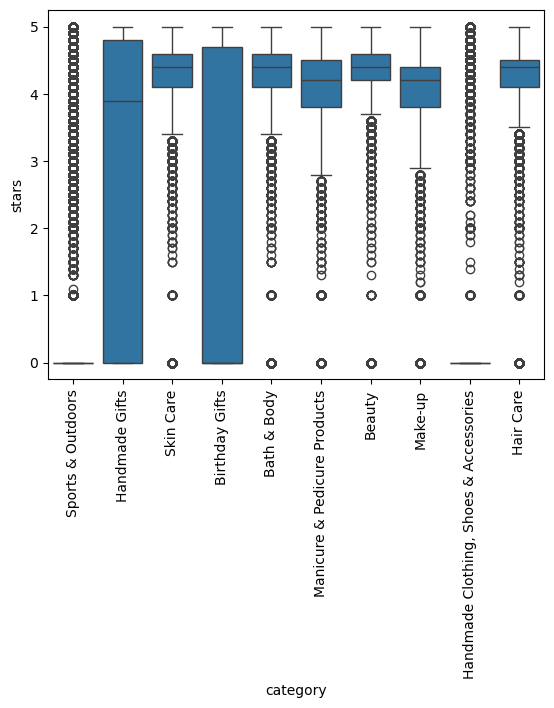

In [119]:
#3a. **Box Plots**: Visualize the distribution of product `ratings` based on their `category` using side-by-side box plots. 
#Filter out the top 10 categories based on count for better visualization.

sns.boxplot(data=df_ex_outliers_top_10, x="category", y="stars", legend=False)
plt.xticks(rotation=90)
plt.show()

In [124]:
#3b Which categories receive highest median rating
mean_cat_rating = df_ex_outliers.groupby("category")['stars'].median()
display(mean_cat_rating.sort_values(ascending=False))

category
Computer Memory                 4.7
Building & Construction Toys    4.6
Office Paper Products           4.6
Luxury Food & Drink             4.6
Kids' Play Figures              4.6
                               ... 
Hockey Shoes                    0.0
Hi-Fi Receivers & Separates     0.0
Handmade Kitchen & Dining       0.0
Handmade Jewellery              0.0
eBook Readers & Accessories     0.0
Name: stars, Length: 296, dtype: float64

### Part 3: Investigating the Interplay Between Product Prices and Ratings

**Objective**: Analyze how product ratings (`stars`) correlate with product prices.

In [128]:
#1 **Correlation Coefficients**: Calculate the correlation coefficient between `price` and `stars`.
correlation = df["price"].corr(df["stars"])
correlation

-0.1249067326214861

In [129]:
spear_correlation = df['price'].corr(df['stars'], method='spearman')
spear_correlation

-0.1331642546243379

**Question:** Is there a significant correlation between product price and its rating
**Answer:** No, not a significant one.

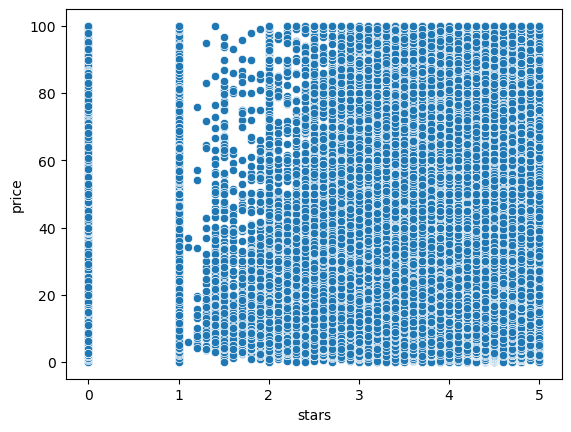

In [131]:
#2. **Visualizations**: Use a scatter plot to visualize the relationship between product rating and price. What patterns can you observe?
sns.scatterplot(data=df_ex_outliers, x="stars", y="price")
plt.show()

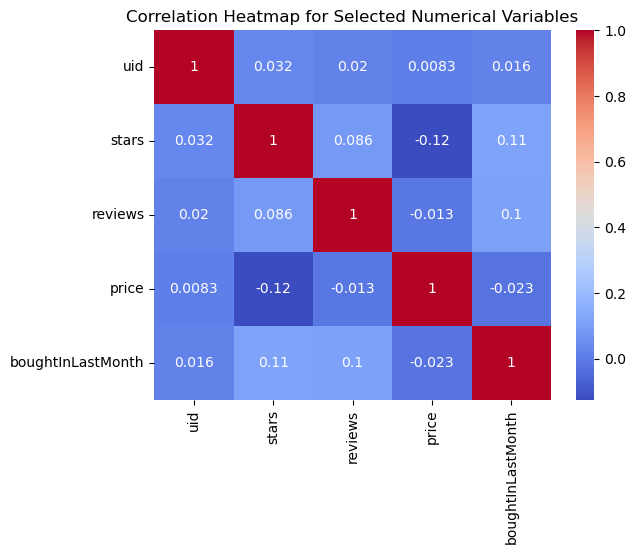

In [136]:
#2a Use a correlation heatmap to visualize correlations between all numerical variables.
df_numerical = df.select_dtypes("number")
num_corr = df_numerical.corr()

# Drawing the heatmap for the numerical columns
sns.heatmap(num_corr, annot=True, cmap="coolwarm")

plt.title("Correlation Heatmap for Selected Numerical Variables")
plt.show()

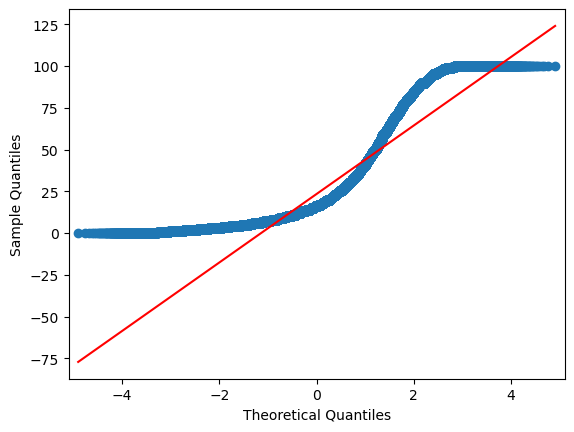

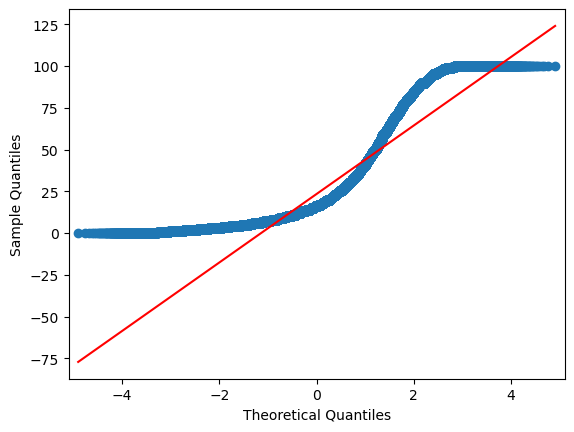

In [138]:
#2b Examine if product prices typically follow a normal distribution using a QQ plot
import statsmodels.api as sm

sm.qqplot(df_ex_outliers['price'], line="s")

**Answer:** Prices do not have a normal distribution. The mean is very low and there are many low prices.